# 02 - Campaign Funnel and Customer Segments

**Goal:** describe what happened in each experiment group, using SQL for the
aggregation and Python only for display and charts.

Part A (day 3) builds the campaign funnel and revenue metrics per group.
Part B (day 4) profiles customer segments.

**How to read this notebook:** everything here is *descriptive*. It shows the size of
the differences between groups, but not whether they could be due to chance. Formal
tests follow in `03_ab_test.ipynb`, using the rules fixed in `analysis_plan.md`.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.db import get_engine

pd.set_option("display.max_columns", 50)

SQL_DIR = ROOT / "sql"
FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

engine = get_engine()

In [2]:
def run_sql(filename):
    """Run one .sql file from the sql/ folder and return the result as a DataFrame."""
    query = (SQL_DIR / filename).read_text(encoding="utf-8")
    with engine.connect() as conn:
        result = pd.read_sql(text(query), conn)

    # MySQL returns DECIMAL values as Python Decimal objects; convert them to float
    for col in result.columns:
        if col != "segment":
            result[col] = result[col].astype(float)
            if (result[col] % 1 == 0).all():  # whole numbers such as counts
                result[col] = result[col].astype(int)
    return result

# Part A - Campaign funnel (day 3)

## 1. Funnel per group

The funnel has three stages, all counted per customer assigned to a group:

1. **Customers:** everyone assigned to the group
2. **Visitors:** customers who visited the website within two weeks
3. **Purchasers:** customers who bought within two weeks

The query lives in `sql/01_funnel.sql` and uses:

- two **CTEs** (`funnel`, then `rates`) so each step reads top to bottom
- **conditional logic** with `CASE` to pick out the control group
- a **window function**, `MAX(...) OVER ()`, to place the control group's rate on
  every row, so each group can be compared with it without a self-join

In [3]:
funnel = run_sql("01_funnel.sql")
funnel

,segment,customers,visitors,purchasers,visit_rate_pct,conversion_rate_pct,visit_to_purchase_pct,visit_lift_pp,conversion_lift_pp
0,No E-Mail,21306,2262,122,10.62,0.573,5.39,0.00,0.000
1,Mens E-Mail,21307,3894,267,18.28,1.253,6.86,7.66,0.681
2,Womens E-Mail,21387,3238,189,15.14,0.884,5.84,4.52,0.311


Column guide:

| Column | Meaning |
| --- | --- |
| `visit_rate_pct` | visitors / customers |
| `conversion_rate_pct` | purchasers / customers |
| `visit_to_purchase_pct` | purchasers / visitors |
| `visit_lift_pp` | visit rate minus the control group's visit rate, in percentage points |
| `conversion_lift_pp` | conversion rate minus the control group's, in percentage points |

**Your notes:**

- Visit rate per group, and the lift of each e-mail over control:
  *) Men's Visit Rate = 18.28, Lift Percentage = 7.66
  *) Women's Visit Rate = 15.14, Lift Percentage = 4.52
- Conversion rate per group, and the lift of each e-mail over control:
  *) Men's Conversation Rate = 1.253, Lift Percentage = 0.681
  *) Women's Visit Rate = 0.884, Lift Percentage = 0.311
- Which e-mail looks stronger so far: Mens

## 2. Funnel chart

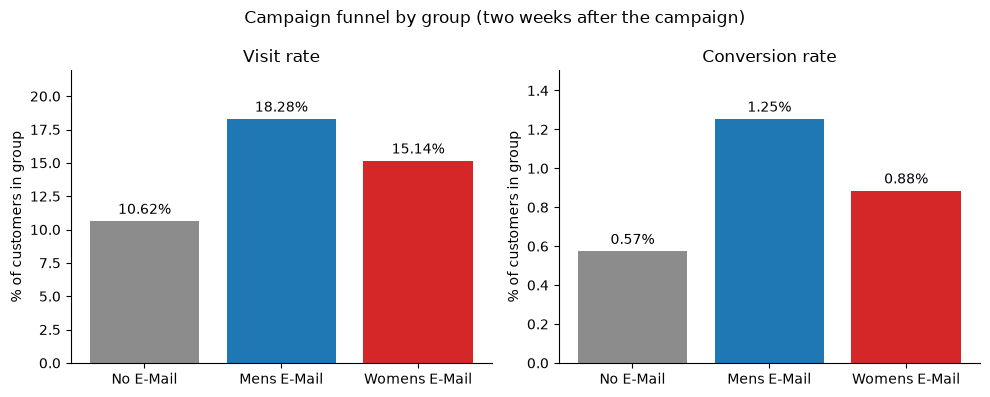

In [4]:
order = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
plot_data = funnel.set_index("segment").loc[order]
colors = ["#8c8c8c", "#1f77b4", "#d62728"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, column, title in [
    (axes[0], "visit_rate_pct", "Visit rate"),
    (axes[1], "conversion_rate_pct", "Conversion rate"),
]:
    bars = ax.bar(plot_data.index, plot_data[column], color=colors)
    ax.bar_label(bars, fmt="%.2f%%", padding=3)
    ax.set_title(title)
    ax.set_ylabel("% of customers in group")
    ax.set_ylim(0, plot_data[column].max() * 1.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Campaign funnel by group (two weeks after the campaign)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_funnel_by_group.png", dpi=150)
plt.show()

The two panels use different vertical scales on purpose: conversion is a much rarer
event than a visit, so on a shared scale its bars would be too small to read.

## 3. Revenue per group

`sql/02_revenue.sql` adds the money side:

- **`spend_per_customer`**: total spend divided by *all* customers in the group,
  including those who spent nothing. This is the fair metric for comparing groups.
- **`avg_order_value`**: total spend divided by purchasers only.
- **`revenue_share_pct`**: each group's share of total revenue, using `SUM(...) OVER ()`.
- **`incremental_revenue_per_10k`**: extra revenue per 10,000 e-mails compared with
  sending nothing.

In [7]:
revenue = run_sql("02_revenue.sql")
revenue

,segment,customers,purchasers,total_spend,spend_per_customer,avg_order_value,revenue_share_pct,spend_lift_per_customer,incremental_revenue_per_10k
0,No E-Mail,21306,122,13908.33,0.6528,114.00,20.7,0.0000,0
1,Mens E-Mail,21307,267,30311.69,1.4226,113.53,45.1,0.7698,7698
2,Womens E-Mail,21387,189,23038.11,1.0772,121.89,34.3,0.4244,4244


**Your notes:**

- Spend per customer per group, and the lift over control:
  *) Men's Spend = 1.4226, Lift Percentage = 0.769
  *) Women's Spend = 1.0772, Lift Percentage = 0.4244
- Incremental revenue per 10,000 e-mails for each e-mail:
  *) Men's Incremental Revenue = 7698
  *) Women's Incremental Revenue = 4244
- Does average order value differ much between groups?
  No, the difference is < 10.

## 4. A trap: comparing "conversion among visitors" between groups

`visit_to_purchase_pct` looks like a natural way to ask "which e-mail brings better
buyers?". It is fine as a description, but it must **not** be read as a causal effect
of the e-mail.

**Why:** randomization makes the three *groups of customers* comparable. It does not
make the three *groups of visitors* comparable, because the e-mail itself changes who
visits. The control group's visitors came without any prompting, so they are probably
the most motivated customers. An e-mail brings in additional, more casual visitors.
A lower visit-to-purchase rate in an e-mail group can therefore simply mean the e-mail
attracted extra browsers, not that it made anyone less likely to buy.

**Rule used in this project:** causal comparisons always divide by *all customers
assigned to the group* (visit rate, conversion rate, spend per customer). Metrics
conditioned on something that happened after assignment, such as "among visitors"
or "among purchasers", are descriptive only.

In [6]:
funnel[["segment", "visitors", "purchasers", "visit_to_purchase_pct"]]

,segment,visitors,purchasers,visit_to_purchase_pct
0,No E-Mail,2262,122,5.39
1,Mens E-Mail,3894,267,6.86
2,Womens E-Mail,3238,189,5.84


## 5. Summary of Part A

- **Visits:** both e-mails brought more customers to the website. The visit rate was
  10.62% without an e-mail, 18.28% with the Mens e-mail (+7.66 percentage points) and
  15.14% with the Womens e-mail (+4.52 percentage points).
- **Purchases:** the conversion rate was 0.573% in the control group, 1.253% for the
  Mens e-mail (+0.681 percentage points, about 2.2 times the control rate) and 0.884%
  for the Womens e-mail (+0.311 percentage points, about 1.5 times). Both lifts are
  above the 0.2 percentage point threshold set in the analysis plan. Purchases are
  rare in every group (122, 267 and 189 purchasers), so these rates carry more
  uncertainty than the visit rates.
- **Revenue:** spend per customer was $0.65 in the control group, $1.42 for the Mens
  e-mail and $1.08 for the Womens e-mail. That is roughly $7,700 and $4,200 of
  additional revenue per 10,000 e-mails. Average order value is similar across groups
  ($114, $114 and $122), so the extra revenue comes from more customers buying, not
  from larger orders.

In [8]:
# Release the database connection when finished for the day
engine.dispose()